In [122]:
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

fetching golub data

In [1]:
import kagglehub

path = kagglehub.dataset_download("crawford/gene-expression")
print(path)

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\zehra\.cache\kagglehub\datasets\crawford\gene-expression\versions\3


In [2]:
from pathlib import Path

files = list(Path(path).rglob("*"))

for file in files:
    if file.is_file():
        print(file.name, "—", file.stat().st_size, "bytes")

actual.csv — 511 bytes
data_set_ALL_AML_independent.csv — 1860352 bytes
data_set_ALL_AML_train.csv — 2039681 bytes


In [3]:
import pandas as pd

data_path = Path(path)

train = pd.read_csv(data_path / "data_set_ALL_AML_train.csv")
test = pd.read_csv(data_path / "data_set_ALL_AML_independent.csv")
actual = pd.read_csv(data_path / "actual.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Labels:", actual.shape)

print("\nTrain columns:", train.columns[:10].tolist())
print("\nLabels preview:")
print(actual.head())

Train: (7129, 78)
Test: (7129, 70)
Labels: (72, 2)

Train columns: ['Gene Description', 'Gene Accession Number', '1', 'call', '2', 'call.1', '3', 'call.2', '4', 'call.3']

Labels preview:
   patient cancer
0        1    ALL
1        2    ALL
2        3    ALL
3        4    ALL
4        5    ALL


In [4]:
train_patients = [col for col in train.columns if col.isdigit()]
test_patients = [col for col in test.columns if col.isdigit()]

print("Training patients:", len(train_patients))
print("Test patients:", len(test_patients))

print("Train IDs:", train_patients)
print("Test IDs:", test_patients)

Training patients: 38
Test patients: 34
Train IDs: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '34', '35', '36', '37', '38', '28', '29', '30', '31', '32', '33']
Test IDs: ['39', '40', '42', '47', '48', '49', '41', '43', '44', '45', '46', '70', '71', '72', '68', '69', '67', '55', '56', '59', '52', '53', '51', '50', '54', '57', '58', '60', '61', '65', '66', '63', '64', '62']


In [5]:
# Keep expression columns only
train_expr = train[train_patients].T
test_expr = test[test_patients].T

# Convert patient IDs to integers
train_expr.index = train_expr.index.astype(int)
test_expr.index = test_expr.index.astype(int)

# Sort patients by ID
train_expr = train_expr.sort_index()
test_expr = test_expr.sort_index()


In [6]:
# Encode ALL = 1, AML = 0
actual["cancer"] = actual["cancer"].map({"ALL": 1, "AML": 0})

In [7]:
# Attach labels using patient IDs
train_expr["target"] = actual.set_index("patient").loc[train_expr.index, "cancer"]
test_expr["target"] = actual.set_index("patient").loc[test_expr.index, "cancer"]

print("Train:", train_expr.shape)
print("Test:", test_expr.shape)
print("Train labels:", train_expr["target"].value_counts())
print("Test labels:", test_expr["target"].value_counts())

Train: (38, 7130)
Test: (34, 7130)
Train labels: target
1    27
0    11
Name: count, dtype: int64
Test labels: target
1    20
0    14
Name: count, dtype: int64


Descriptive Statistics and Data Quality

In [12]:
import numpy as np

X_train = train_expr.drop(columns="target")
X_test = test_expr.drop(columns="target")

print("Missing values in training data:", X_train.isna().sum().sum())
print("Infinite values in training data:",np.isinf(X_train.to_numpy(dtype=float)).sum())
print("Duplicate samples:", X_train.duplicated().sum())
print("Constant features:", (X_train.nunique() <= 1).sum())

Missing values in training data: 0
Infinite values in training data: 0
Duplicate samples: 0
Constant features: 0


In [86]:
for name, X in [("Train", X_train), ("Test", X_test)]:
    values = X.to_numpy()

    print(f"\n--- {name} Descriptive Statistics ---")
    print("Negative values:", (values < 0).sum())
    print("Zero values:", (values == 0).sum())
    print("Minimum:", values.min())
    print("Maximum:", values.max())
    print("Mean:", values.mean())
    print("Median:", np.median(values))
    print("Standard deviation:", values.std())


--- Train Descriptive Statistics ---
Negative values: 77175
Zero values: 738
Minimum: -28400
Maximum: 61228
Mean: 637.6980014913142
Median: 127.0
Standard deviation: 2426.2181600967137

--- Test Descriptive Statistics ---
Negative values: 69999
Zero values: 877
Minimum: -26775
Maximum: 71369
Mean: 599.7512686376276
Median: 114.0
Standard deviation: 2459.487294363926


Raw Expression Distributions — Train vs. Test

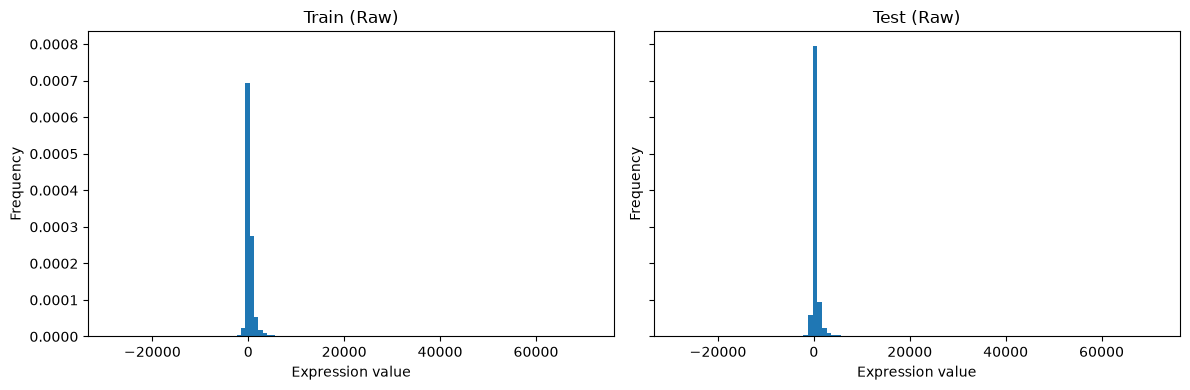

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

for ax, data, title in zip(
    axes,
    [X_train, X_test],
    ["Train (Raw)", "Test (Raw)"]
):
    ax.hist(data.to_numpy().ravel(), bins=100, density = True)
    ax.set_title(title)
    ax.set_xlabel("Expression value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [15]:
# Clip expression values
X_train_clipped = X_train.clip(lower=100, upper=16000)
X_test_clipped = X_test.clip(lower=100, upper=16000)

# Log2 transformation
X_train_log2 = np.log2(X_train_clipped)
X_test_log2 = np.log2(X_test_clipped)

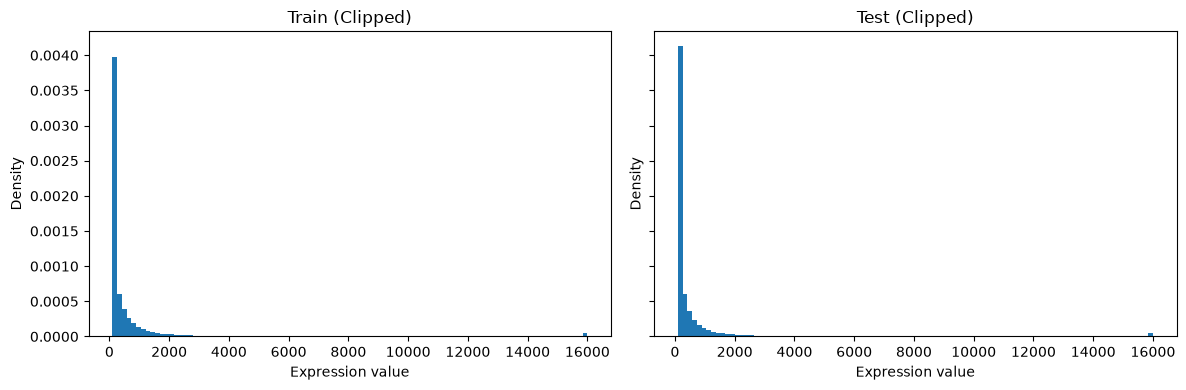

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

for ax, data, title in zip(
    axes,
    [X_train_clipped, X_test_clipped],
    ["Train (Clipped)", "Test (Clipped)"]
):
    ax.hist(data.to_numpy().ravel(), bins=100, density = True)
    ax.set_title(title)
    ax.set_xlabel("Expression value")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

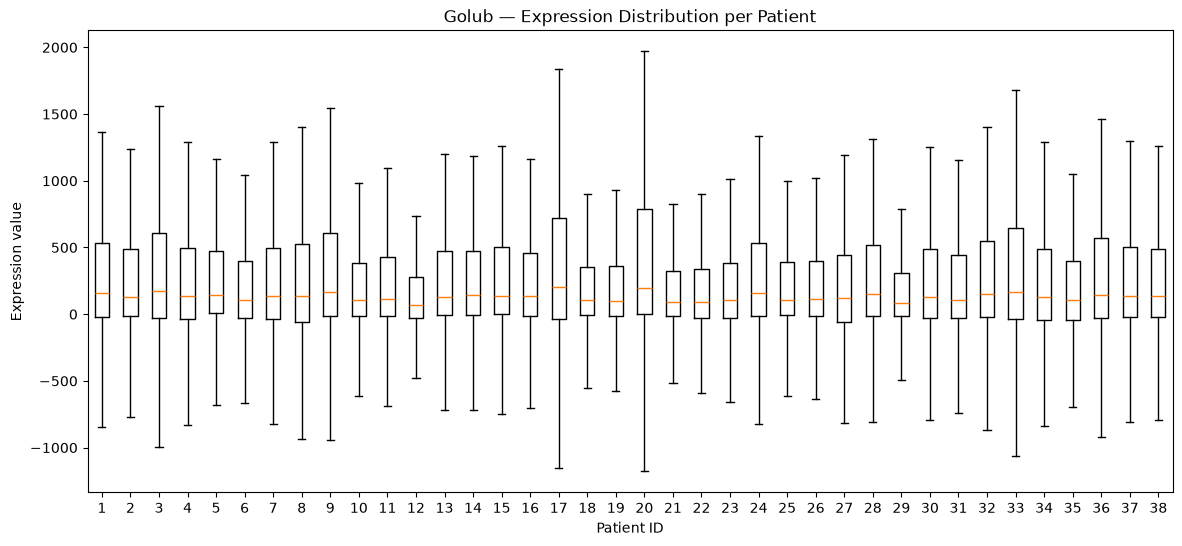

In [89]:
plt.figure(figsize=(14, 6))
plt.boxplot(X_train.T, showfliers=False)
plt.xlabel("Patient ID")
plt.ylabel("Expression value")
plt.title("Golub — Expression Distribution per Patient")
plt.show()

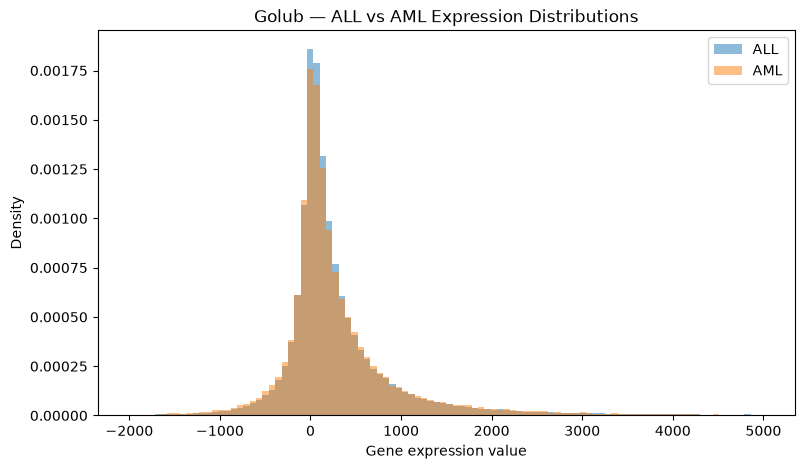

In [18]:
all_values = X_train.loc[train_expr["target"] == 1].to_numpy().flatten()
aml_values = X_train.loc[train_expr["target"] == 0].to_numpy().flatten()

plt.figure(figsize=(9, 5))

plt.hist(all_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="ALL")

plt.hist(aml_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="AML")

plt.xlabel("Gene expression value")
plt.ylabel("Density")
plt.title("Golub — ALL vs AML Expression Distributions")
plt.legend()
plt.show()

In [19]:
gene_variances = X_train.var(axis=0)

print(gene_variances.describe())
print(gene_variances.nlargest(10))

count    7.129000e+03
mean     6.820928e+05
std      3.845060e+06
min      4.769018e+02
25%      8.210373e+03
50%      3.170128e+04
75%      1.295735e+05
max      1.609285e+08
dtype: float64
5709    1.609285e+08
5647    9.014333e+07
5506    6.822979e+07
6605    6.455910e+07
5710    6.425958e+07
18      5.694293e+07
5715    5.456498e+07
4016    4.963480e+07
5228    4.168747e+07
41      4.010845e+07
dtype: float64


Expression Distributions Before and After Transformation

In [ ]:
X_train_log = np.sign(X_train) * np.log2(1 + np.abs(X_train))
X_train_asinh = np.arcsinh(X_train)

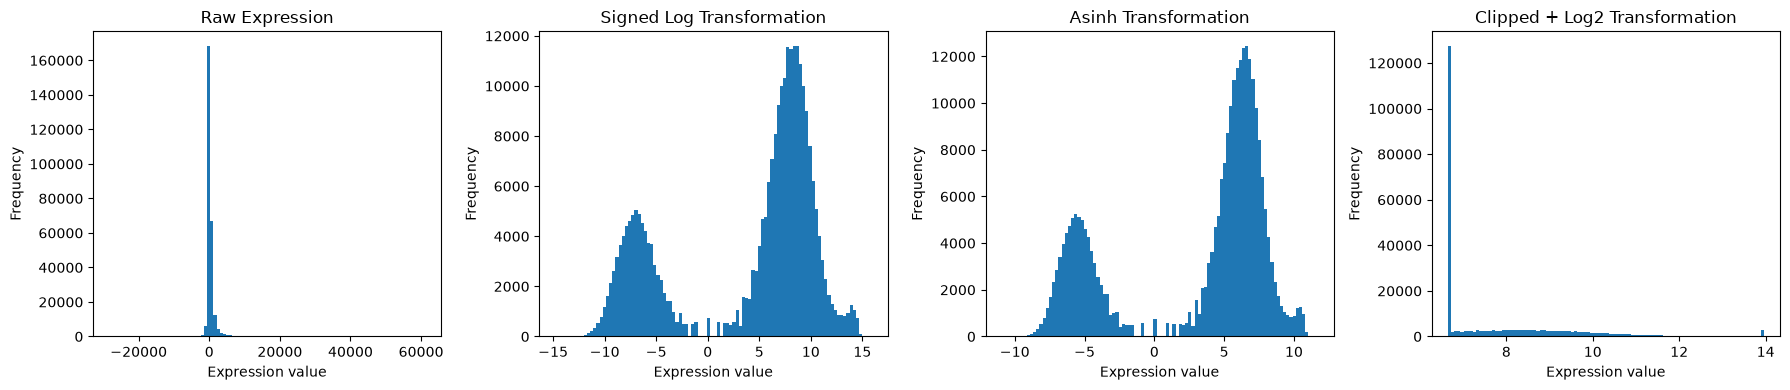

In [90]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

datasets = [
    (X_train, "Raw Expression"),
    (X_train_log, "Signed Log Transformation"),
    (X_train_asinh, "Asinh Transformation"),
    (X_train_log2, "Clipped + Log2 Transformation")
]

for ax, (data, title) in zip(axes, datasets):
    ax.hist(data.to_numpy().ravel(), bins=100)
    ax.set_title(title)
    ax.set_xlabel("Expression value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

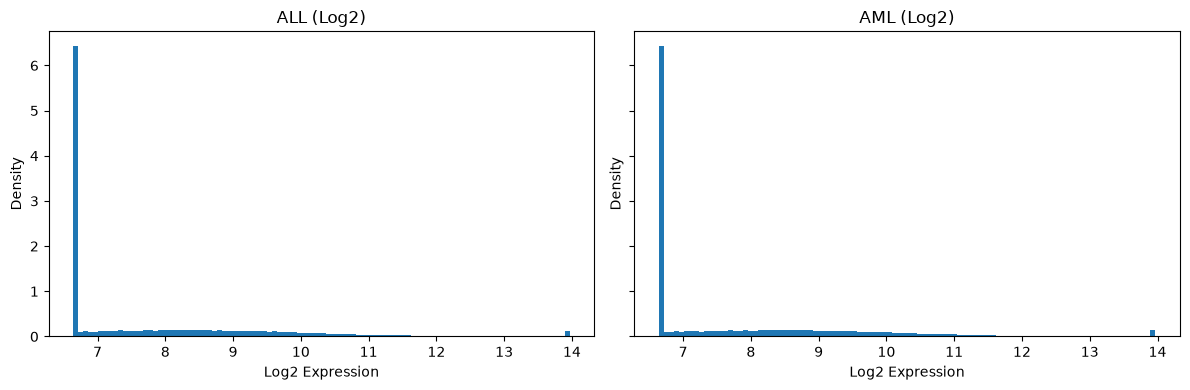

In [24]:
all_log2 = X_train_log2.loc[train_expr["target"] == 1]
aml_log2 = X_train_log2.loc[train_expr["target"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

for ax, data, title in zip(
    axes,
    [all_log2, aml_log2],
    ["ALL (Log2)", "AML (Log2)"]
):
    ax.hist(data.to_numpy().ravel(), bins=100, density=True)
    ax.set_title(title)
    ax.set_xlabel("Log2 Expression")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_log2)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

pc1_loadings = pd.Series(pca.components_[0], index=X_train.columns)

In [27]:
print(X_pca.shape)
cumsum = np.cumsum(pca.explained_variance_ratio_)

(38, 38)


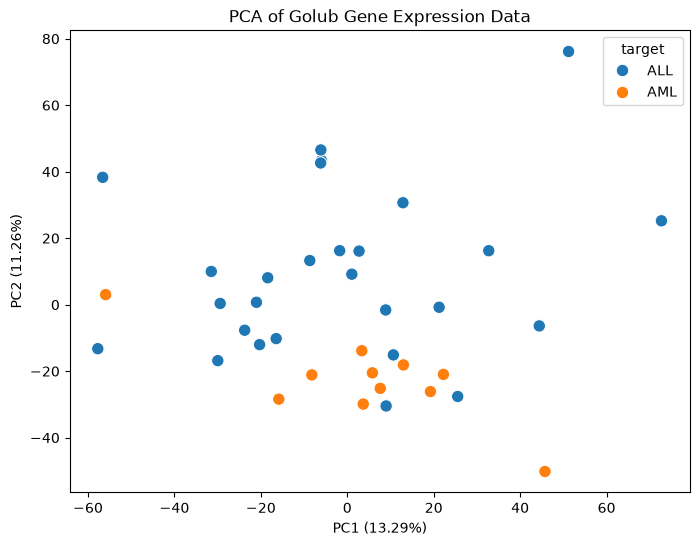

In [ ]:
import seaborn as sns
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=train_expr["target"].map({1: "ALL", 0: "AML"}),
    s=80
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")
plt.title("PCA of Golub Gene Expression Data")
plt.show()

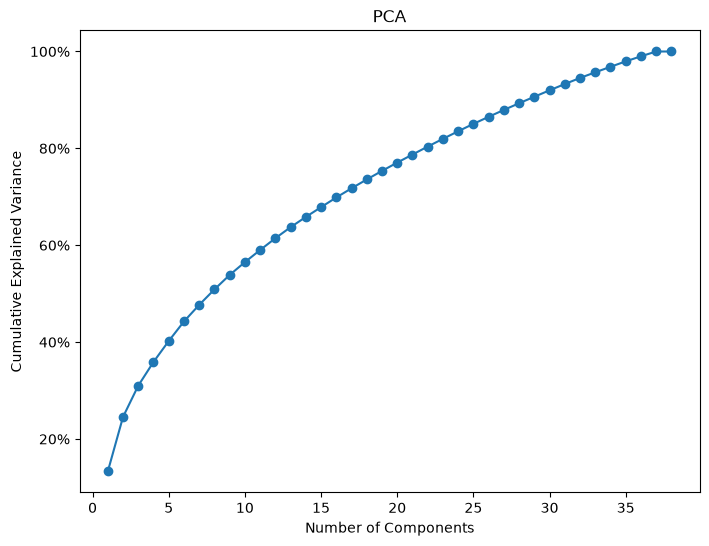

In [92]:
from matplotlib.ticker import PercentFormatter



line_plot = plt.figure(figsize=(8, 6))
plt.plot(np.arange(1, len(cumsum) + 1), cumsum, marker="o")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA")
plt.show()

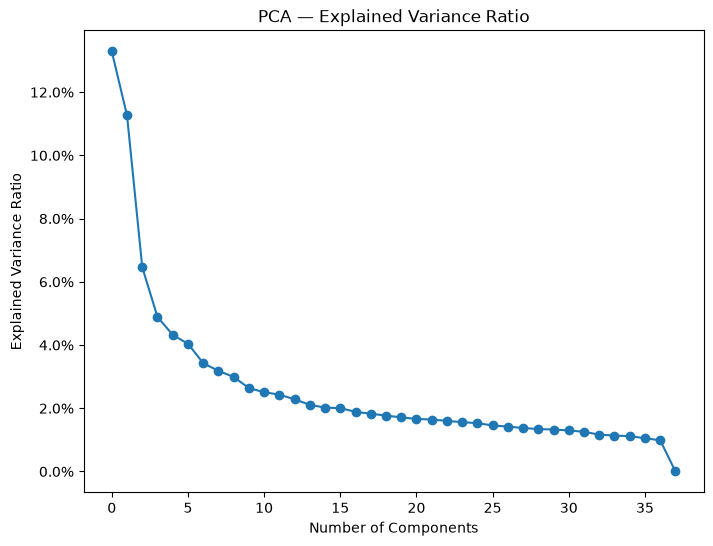

In [30]:
line_plot_vr = plt.figure(figsize=(8, 6))
plt.plot(pca.explained_variance_ratio_, marker="o")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Number of Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA — Explained Variance Ratio")
plt.show()

In [31]:
pc1_loadings.loc[pc1_loadings.abs().nlargest(10).index]

5833    0.031184
7012    0.030750
5995    0.030740
430     0.030363
5438    0.030081
3835    0.029936
4738    0.029902
3439    0.029875
3222    0.029873
3754    0.029610
dtype: float64

In [32]:
from umap import UMAP

In [33]:
import umap

In [ ]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
X_umap = reducer.fit_transform(X_scaled)

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


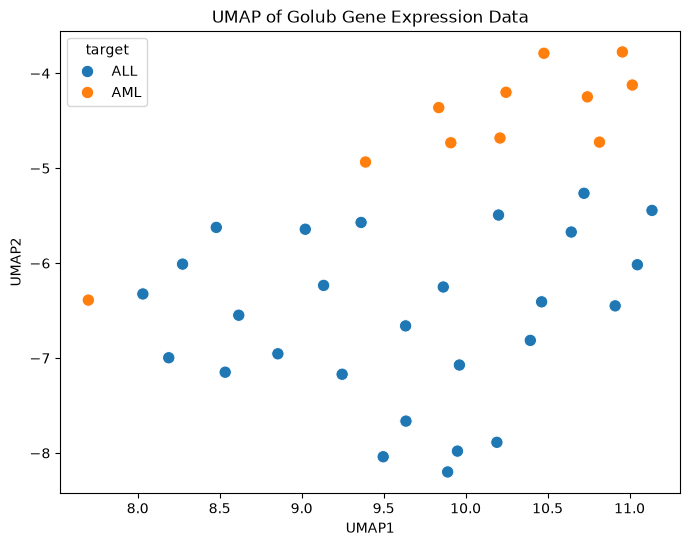

In [35]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_umap[:, 0],
    y=X_umap[:, 1],
    hue=train_expr["target"].map({1: "ALL", 0: "AML"}),
    s=80
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP of Golub Gene Expression Data")
plt.show()

In [104]:

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# 1. Exclude constant probes
valid_mask = X_train_log2.nunique(axis=0) > 1
valid_probes = X_train_log2.columns[valid_mask]

# 2. Separate ALL and AML samples
all_data = X_train_log2.loc[
    train_expr["target"] == 1, valid_probes
]
aml_data = X_train_log2.loc[
    train_expr["target"] == 0, valid_probes
]

# 3. Welch's t-test
t_stat, p_value = ttest_ind(
    all_data,
    aml_data,
    axis=0,
    equal_var=False
)

# 4. Exclude any remaining invalid tests
finite_mask = np.isfinite(p_value)

valid_probes = valid_probes[finite_mask]
t_stat = t_stat[finite_mask]
p_value = p_value[finite_mask]

all_data = all_data.loc[:, valid_probes]
aml_data = aml_data.loc[:, valid_probes]

# 5. Benjamini-Hochberg FDR correction
rejected, pvals_corrected, _, _ = multipletests(
    p_value,
    alpha=0.05,
    method="fdr_bh"
)

# 6. Summary
print("Total probes:", X_train_log2.shape[1])
print("Valid probes tested:", len(p_value))
print("Significant probes (FDR < 0.05):", rejected.sum())

# 7. Probe-level statistics
golub_gene_stats = pd.DataFrame({
    "probe": train.loc[valid_probes, "Gene Accession Number"].values,
    "t_stat": t_stat,
    "p_value": p_value,
    "p_adjusted": pvals_corrected,
    "mean_difference": all_data.mean().values - aml_data.mean().values
})

golub_gene_stats = golub_gene_stats.sort_values("p_adjusted")

display(golub_gene_stats.head(20))

# 8. Select top 20 and top 50 probes
ranked_probes = golub_gene_stats.index

X_top20 = X_train_log2.loc[:, ranked_probes[:20]]
X_top50 = X_train_log2.loc[:, ranked_probes[:50]]


Total probes: 7129
Valid probes tested: 6079
Significant probes (FDR < 0.05): 612


c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)


,probe,t_stat,p_value,p_adjusted,mean_difference
4172,X95735_at,-9.640968,1.209693e-10,7.353724e-07,-3.110457
1760,M55150_at,-7.853197,2.791747e-09,8.485516e-06,-1.306256
2388,U12471_cds1_at,-7.262809,3.428483e-08,5.052369e-05,-0.929422
2863,U50136_rna1_at,-8.480939,4.972638e-08,5.052369e-05,-1.402700
4328,Y12670_at,-7.696738,3.497184e-08,5.052369e-05,-1.753139
5853,M31523_at,7.473562,4.986710e-08,5.052369e-05,1.950013
1635,M27891_at,-9.216333,1.035162e-07,7.865937e-05,-4.740784
3318,U82759_at,-6.998291,1.009490e-07,7.865937e-05,-1.898160
3493,X04085_rna1_at,-6.528176,1.599142e-07,1.080132e-04,-2.069905
4934,U22376_cds2_s_at,7.780741,1.858125e-07,1.129554e-04,2.432758


In [102]:
class_labels = train_expr.loc[X_top20.index, "target"].map({
    1: "ALL",
    0: "AML"
})

class_colors = class_labels.map({
    "ALL": "steelblue",
    "AML": "darkorange"
})


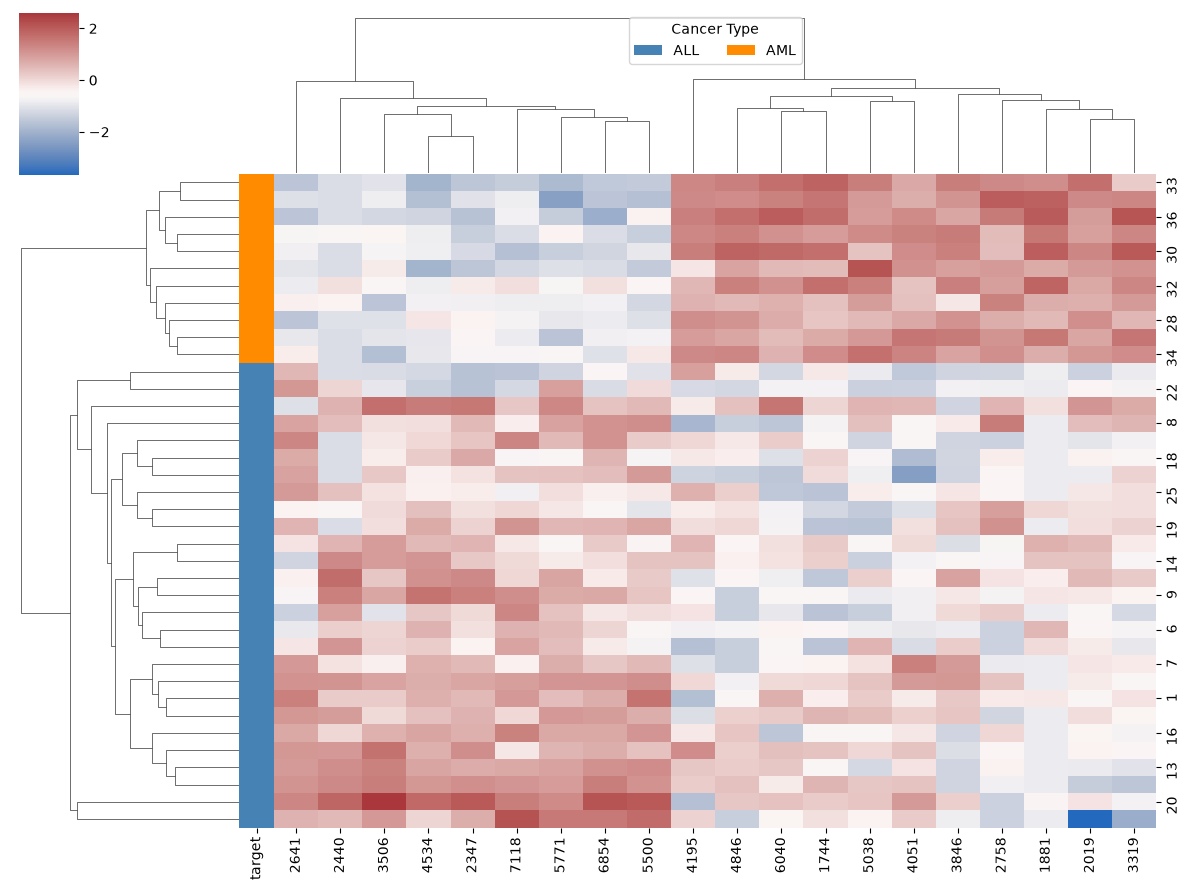

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

g20 = sns.clustermap(
    X_top20,
    z_score=1,
    cmap="vlag",
    method="average",
    metric="euclidean",
    figsize=(12, 9),
    row_colors = class_colors
)
g20.ax_heatmap.legend(
    handles=[
        Patch(facecolor="steelblue", label="ALL"),
        Patch(facecolor="darkorange", label="AML")
    ],
    title="Cancer Type",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.25),
    ncol=2
)
plt.show()

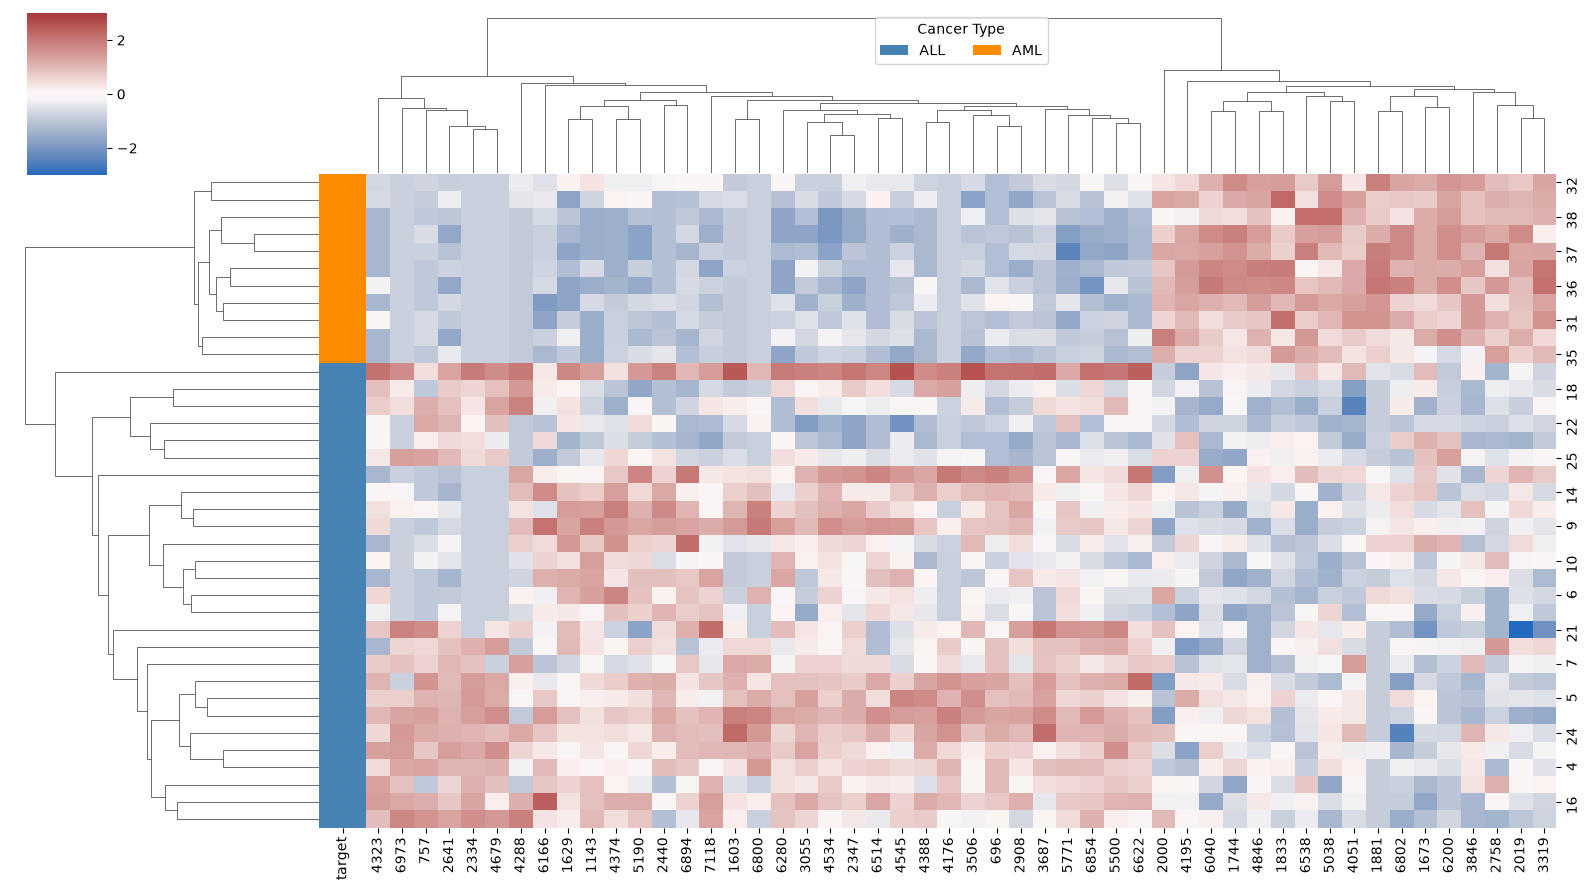

In [ ]:
g50 = sns.clustermap(
    X_top50,
    z_score=1,
    cmap="vlag",
    method="average",
    metric="euclidean",
    figsize=(16, 9),
    row_colors=class_colors,
    xticklabels=True,
    center=0,
    vmin=-3,
    vmax=3
)

g50.ax_heatmap.legend(
    handles=[
        Patch(facecolor="steelblue", label="ALL"),
        Patch(facecolor="darkorange", label="AML")
    ],
    title="Cancer Type",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.25),
    ncol=2
)

plt.show()

Batch Effect Check

In [45]:
X_test = test_expr.drop(columns=["target"])

In [46]:
print(X_test.shape)
print(X_train.shape)
print(X_test.columns.equals(X_train.columns))

(34, 7129)
(38, 7129)
True


In [47]:
print("Training:")
print(X_train.stack().describe())

print("\nIndependent test:")
print(X_test.stack().describe())

Training:
count    270902.000000
mean        637.698001
std        2426.222638
min      -28400.000000
25%         -20.000000
50%         127.000000
75%         466.000000
max       61228.000000
dtype: float64

Independent test:
count    242386.000000
mean        599.751269
std        2459.492368
min      -26775.000000
25%         -21.000000
50%         114.000000
75%         410.000000
max       71369.000000
dtype: float64


In [117]:
train_gene_means = X_train_log2.mean(axis=0)
test_gene_means = X_test_log2.mean(axis=0)

mean_shifts = (test_gene_means - train_gene_means).abs()

print(mean_shifts.describe())
print("Median absolute gene-wise shift:", mean_shifts.median())

count    7129.000000
mean        0.166988
std         0.193237
min         0.000000
25%         0.023388
50%         0.102590
75%         0.256088
max         2.493928
dtype: float64
Median absolute gene-wise shift: 0.10258976286883037


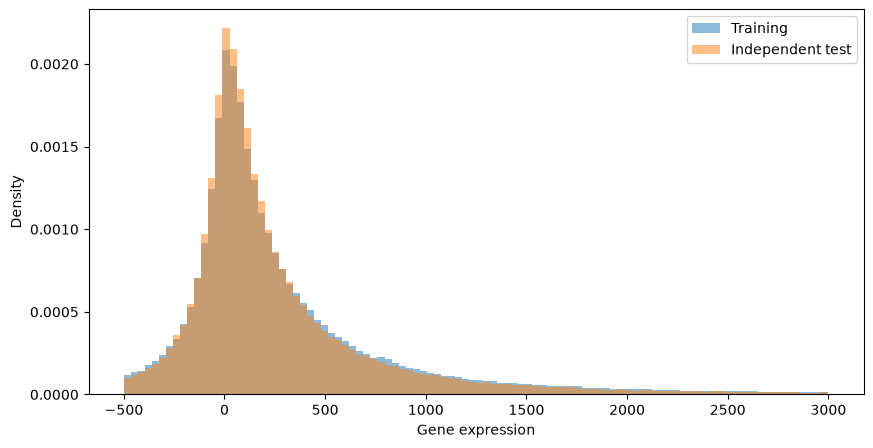

In [48]:
train_values = X_train.to_numpy().ravel()
test_values = X_test.to_numpy().ravel()

plt.figure(figsize=(10, 5))

plt.hist(train_values, bins=100, range=(-500, 3000),
         density=True, alpha=0.5, label="Training")

plt.hist(test_values, bins=100, range=(-500, 3000),
         density=True, alpha=0.5, label="Independent test")

plt.xlabel("Gene expression")
plt.ylabel("Density")
plt.legend()
plt.show()

In [49]:
train_all = train_expr.loc[train_expr["target"] == 1].drop(columns="target")
test_all = test_expr.loc[test_expr["target"] == 1].drop(columns="target")

train_aml = train_expr.loc[train_expr["target"] == 0].drop(columns="target")
test_aml = test_expr.loc[test_expr["target"] == 0].drop(columns="target")

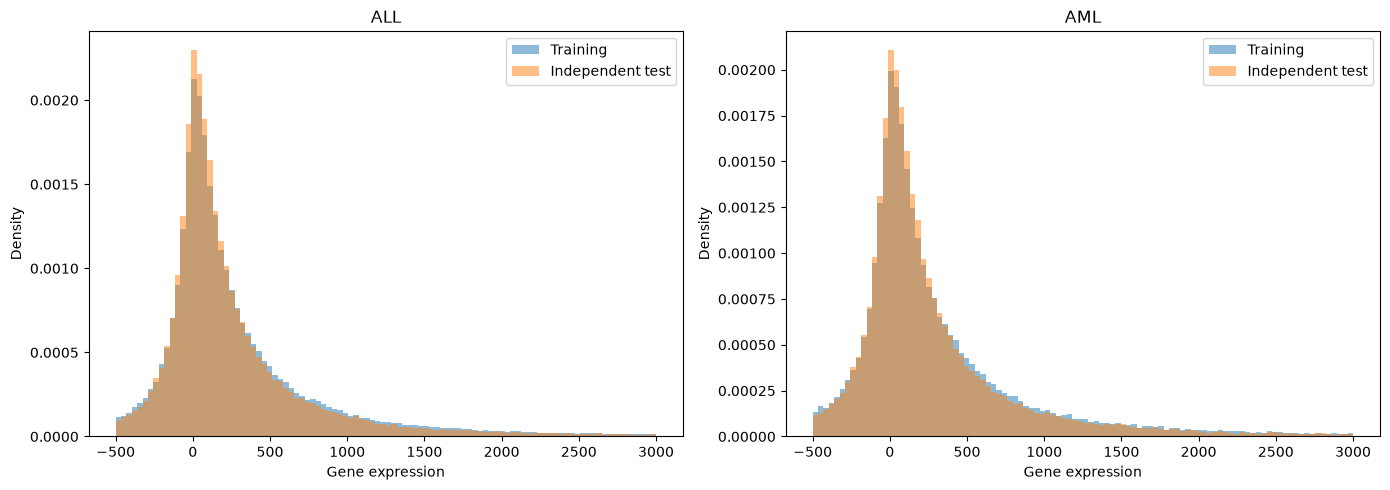

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, train_subset, test_subset, title in zip(
    axes,
    [train_all, train_aml],
    [test_all, test_aml],
    ["ALL", "AML"]
):
    ax.hist(train_subset.to_numpy().ravel(), bins=100, range=(-500, 3000),
            density=True, alpha=0.5, label="Training")
    ax.hist(test_subset.to_numpy().ravel(), bins=100, range=(-500, 3000),
            density=True, alpha=0.5, label="Independent test")

    ax.set_title(title)
    ax.set_xlabel("Gene expression")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

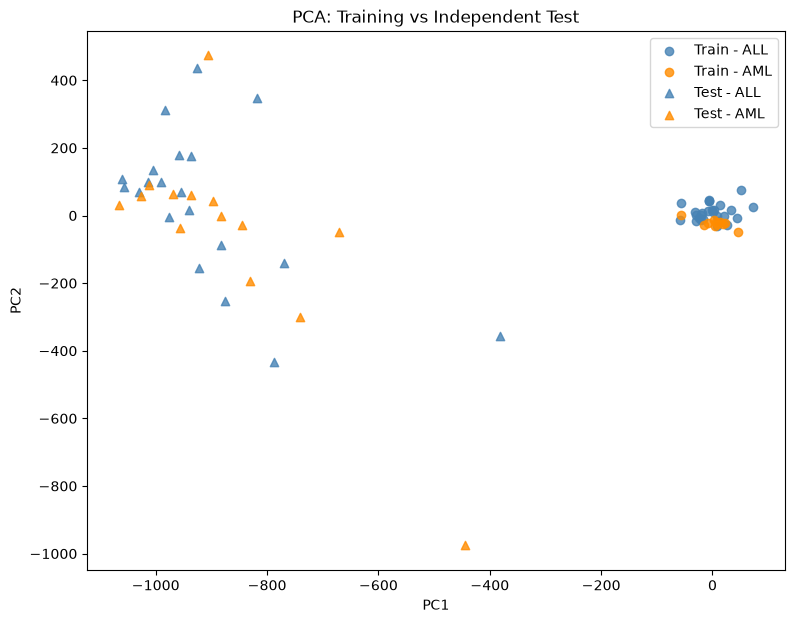

In [ ]:
X_train_pca = X_pca
X_test_pca = pca.transform(scaler.transform(X_test_log2))

fig, ax = plt.subplots(figsize=(9, 7))

for pca_coords, labels, marker, dataset in [
    (X_train_pca, train_expr["target"], "o", "Train"),
    (X_test_pca, test_expr["target"], "^", "Test")
]:
    for target, color, cancer in [
        (1, "steelblue", "ALL"),
        (0, "darkorange", "AML")
    ]:
        mask = labels.to_numpy() == target

        ax.scatter(
            pca_coords[mask, 0],
            pca_coords[mask, 1],
            c=color,
            marker=marker,
            alpha=0.8,
            label=f"{dataset} - {cancer}"
        )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA: Training vs Independent Test")
ax.legend()
plt.show()

Shipp EDA (DLBCL vs FL)

In [54]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE68nnn/GSE68895/matrix/GSE68895_series_matrix.txt.gz"

shipp_raw = pd.read_csv(
    url,
    sep="\t",
    comment="!",
    index_col=0
)

print(shipp_raw.shape)
print(shipp_raw.iloc[:5, :5])

(7129, 77)
               GSM1685734  GSM1685735  GSM1685736  GSM1685737  GSM1685738
ID_REF                                                                   
A28102_at           151.3       504.6       234.7       375.7       137.8
AB000114_at          20.6        70.2       176.8       151.4        13.8
AB000115_at         248.1       385.1       901.5       390.6       337.0
AB000220_at          73.7       312.6       133.9       246.9       330.1
AB000381_s_at        25.2        29.0        39.4         6.0         8.9


In [55]:
shipp_expr = shipp_raw.T

print(shipp_expr.shape)
print(shipp_expr.iloc[:3, :5])

(77, 7129)
ID_REF      A28102_at  AB000114_at  AB000115_at  AB000220_at  AB000381_s_at
GSM1685734      151.3         20.6        248.1         73.7           25.2
GSM1685735      504.6         70.2        385.1        312.6           29.0
GSM1685736      234.7        176.8        901.5        133.9           39.4


In [56]:
import gzip
import urllib.request

with urllib.request.urlopen(url) as response:
    with gzip.open(response, "rt") as f:
        for line in f:
            if line.startswith("!Sample_characteristics_ch1"):
                print(line[:500])

!Sample_characteristics_ch1	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"d
!Sample_characteristics_ch1	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"ce

In [57]:
import csv

with urllib.request.urlopen(url) as response:
    with gzip.open(response, "rt") as f:
        for line in f:
            if line.startswith("!Sample_characteristics_ch1"):
                values = next(csv.reader([line], delimiter="\t"))[1:]

                if all(v.startswith("disease state:") for v in values):
                    diagnoses = [v.split(":", 1)[1].strip() for v in values]
                    break

print(pd.Series(diagnoses).value_counts())

Diffuse large B-cell Lymphoma    58
Follicular Lymphoma              19
Name: count, dtype: int64


In [58]:
shipp_expr["target"] = [
    1 if diagnosis == "Diffuse large B-cell Lymphoma" else 0
    for diagnosis in diagnoses
]

In [59]:
print(shipp_expr.shape)
print(shipp_expr["target"].value_counts())
print(shipp_expr.iloc[:3, -3:])

(77, 7130)
target
1    58
0    19
Name: count, dtype: int64
ID_REF      Z97054_xpt2_at  Z97074_at  target
GSM1685734           372.7      139.8       1
GSM1685735            90.4      142.6       1
GSM1685736           431.4      117.7       1


In [60]:
golub_probes = set(train["Gene Accession Number"].dropna())
shipp_probes = set(shipp_expr.columns)

common_probes = golub_probes & shipp_probes

print("Golub probes:", len(golub_probes))
print("Shipp probes:", len(shipp_probes))
print("Common probes:", len(common_probes))

Golub probes: 7129
Shipp probes: 7130
Common probes: 7129


In [61]:
print(train["Gene Accession Number"].duplicated().sum())
print(shipp_expr.columns.duplicated().sum())

0
0


In [62]:
golub_train = train.set_index("Gene Accession Number")
golub_test = test.set_index("Gene Accession Number")

In [63]:
print(golub_train.columns[:8].tolist())
print(golub_test.columns[:8].tolist())

['Gene Description', '1', 'call', '2', 'call.1', '3', 'call.2', '4']
['Gene Description', '39', 'call', '40', 'call.1', '42', 'call.2', '47']


In [64]:
shipp_expr = shipp_expr.drop(columns="target")

In [65]:
golub_train_expr = golub_train.loc[
    :, golub_train.columns.str.isdigit()
].T

golub_test_expr = golub_test.loc[
    :, golub_test.columns.str.isdigit()
].T

golub_all = pd.concat([golub_train_expr, golub_test_expr])

In [66]:
golub_aligned = golub_all[shipp_expr.columns]
shipp_aligned = shipp_expr[golub_aligned.columns]

print(golub_aligned.shape)
print(shipp_aligned.shape)
print(golub_aligned.columns.equals(shipp_aligned.columns))

(72, 7129)
(77, 7129)
True


In [67]:
matches = []

for golub_id, golub_row in golub_aligned.iterrows():
    for shipp_id, shipp_row in shipp_aligned.iterrows():
        if np.array_equal(golub_row.to_numpy(), shipp_row.to_numpy()):
            matches.append((golub_id, shipp_id))

print("Identical patient profiles:", matches)
print("Number of matches:", len(matches))

Identical patient profiles: []
Number of matches: 0


data quality


In [68]:
print("Shape:", shipp_expr.shape)
print("Missing values:", shipp_expr.isna().sum().sum())
print("Infinite values:", np.isinf(shipp_expr.to_numpy()).sum())
print("Negative values:", (shipp_expr < 0).sum().sum())
print("Duplicate samples:", shipp_expr.duplicated().sum())
print("Constant probes:", (shipp_expr.nunique() <= 1).sum())

Shape: (77, 7129)
Missing values: 0
Infinite values: 0
Negative values: 0
Duplicate samples: 0
Constant probes: 0


descriptive statistics

In [69]:
values = shipp_expr.to_numpy().ravel()

print("Minimum:", np.min(values))
print("Maximum:", np.max(values))
print("Mean:", np.mean(values))
print("Median:", np.median(values))
print("Standard deviation:", np.std(values))
print("25th percentile:", np.percentile(values, 25))
print("75th percentile:", np.percentile(values, 75))
print("99th percentile:", np.percentile(values, 99))
print("99.9th percentile:", np.percentile(values, 99.9))

Minimum: 0.1
Maximum: 89141.8
Mean: 840.0159862861223
Median: 197.5
Standard deviation: 2930.811474495387
25th percentile: 61.1
75th percentile: 555.1
99th percentile: 15405.640000000025
99.9th percentile: 36698.671200000725


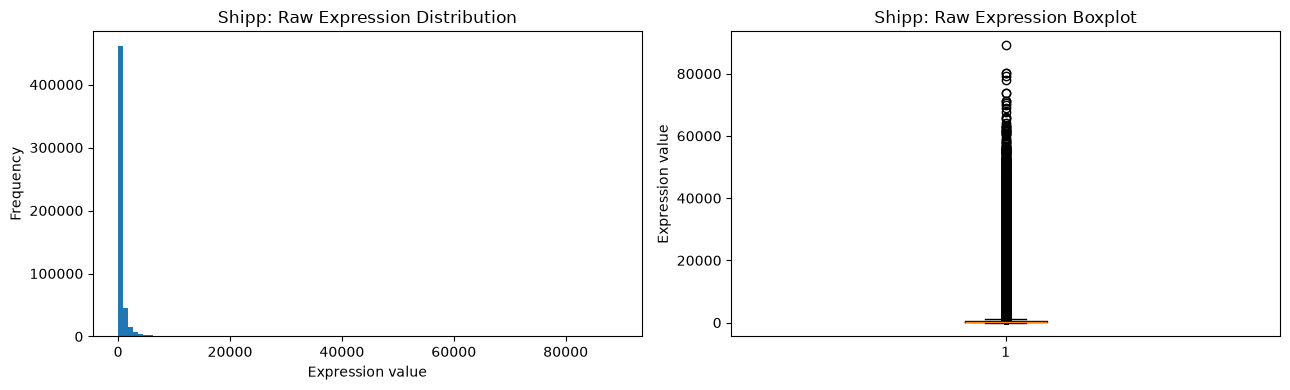

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(values, bins=100)
axes[0].set_title("Shipp: Raw Expression Distribution")
axes[0].set_xlabel("Expression value")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(values)
axes[1].set_title("Shipp: Raw Expression Boxplot")
axes[1].set_ylabel("Expression value")

plt.tight_layout()
plt.show()

log2 transformation


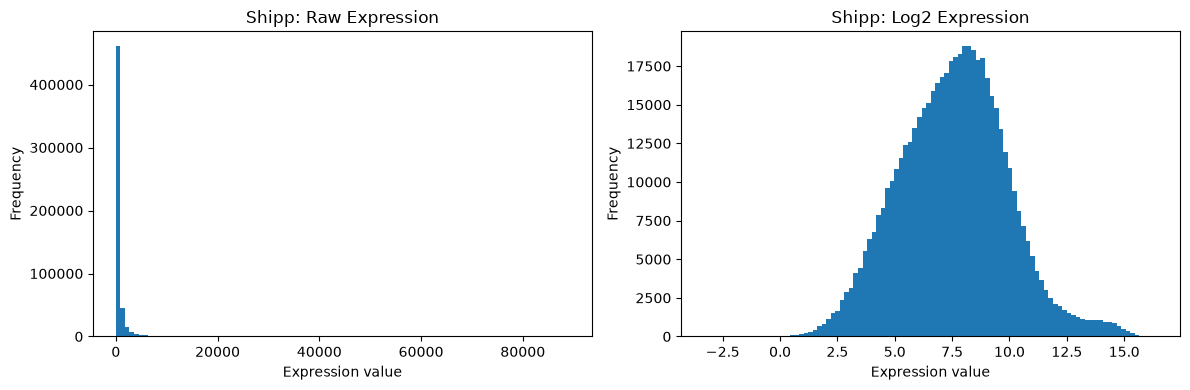

In [71]:
X_shipp_log = np.log2(shipp_expr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(shipp_expr.to_numpy().ravel(), bins=100)
axes[0].set_title("Shipp: Raw Expression")

axes[1].hist(X_shipp_log.to_numpy().ravel(), bins=100)
axes[1].set_title("Shipp: Log2 Expression")

for ax in axes:
    ax.set_xlabel("Expression value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

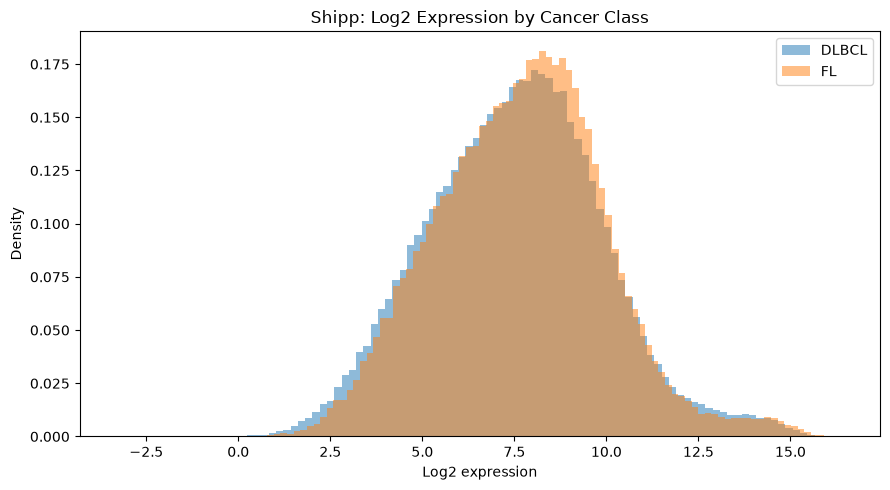

In [72]:
shipp_expr["target"] = [
    1 if diagnosis == "Diffuse large B-cell Lymphoma" else 0
    for diagnosis in diagnoses
]

dlbcl_log = X_shipp_log.loc[shipp_expr["target"] == 1]
fl_log = X_shipp_log.loc[shipp_expr["target"] == 0]

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(dlbcl_log.to_numpy().ravel(), bins=100,
        density=True, alpha=0.5, label="DLBCL")

ax.hist(fl_log.to_numpy().ravel(), bins=100,
        density=True, alpha=0.5, label="FL")

ax.set_title("Shipp: Log2 Expression by Cancer Class")
ax.set_xlabel("Log2 expression")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

PCA with explained variance

In [73]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

shipp_scaler = StandardScaler()
X_shipp_scaled = shipp_scaler.fit_transform(X_shipp_log)

shipp_pca = PCA()
X_shipp_pca = shipp_pca.fit_transform(X_shipp_scaled)

print("PC1 explained variance:", shipp_pca.explained_variance_ratio_[0])
print("PC2 explained variance:", shipp_pca.explained_variance_ratio_[1])
print("Cumulative PC1 + PC2:", shipp_pca.explained_variance_ratio_[:2].sum())

PC1 explained variance: 0.22200867751106693
PC2 explained variance: 0.06766672205601079
Cumulative PC1 + PC2: 0.2896753995670777


Plot PCA by cancer class

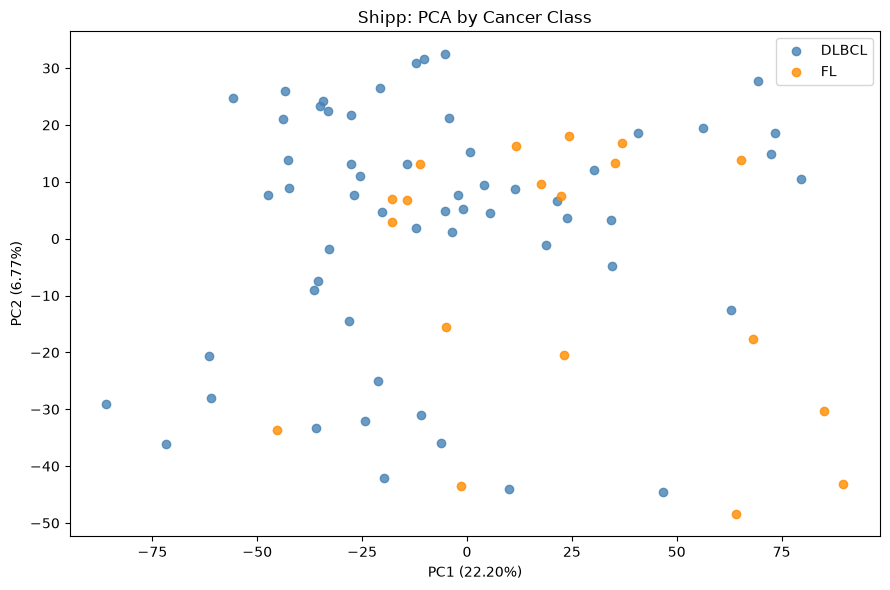

In [74]:
fig, ax = plt.subplots(figsize=(9, 6))

for target, label, color in [
    (1, "DLBCL", "steelblue"),
    (0, "FL", "darkorange")
]:
    mask = shipp_expr["target"].to_numpy() == target

    ax.scatter(
        X_shipp_pca[mask, 0],
        X_shipp_pca[mask, 1],
        label=label,
        color=color,
        alpha=0.8
    )

ax.set_xlabel("PC1 (22.20%)")
ax.set_ylabel("PC2 (6.77%)")
ax.set_title("Shipp: PCA by Cancer Class")
ax.legend()

plt.tight_layout()
plt.show()

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


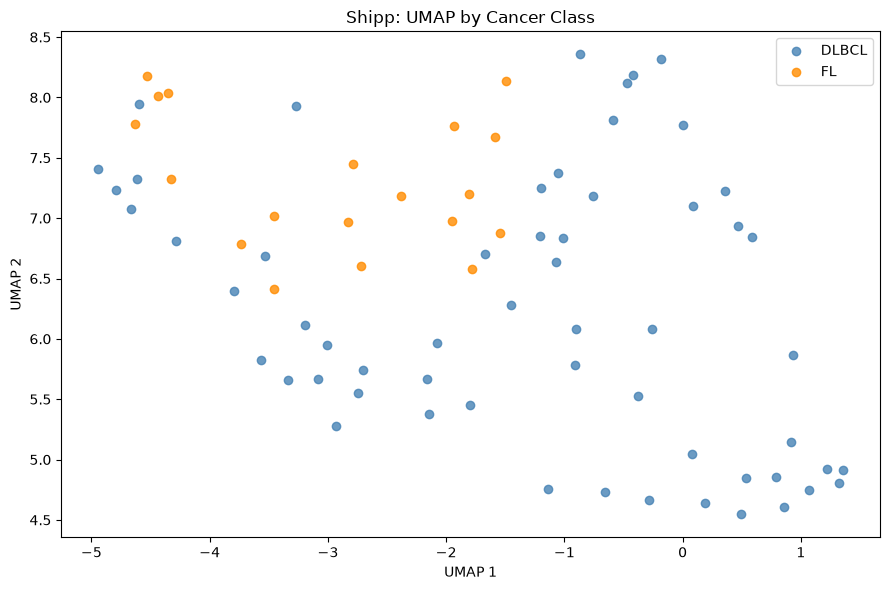

In [ ]:
shipp_umap = umap.UMAP(
    n_neighbors=10,
    min_dist=0.1,
    random_state=SEED
)

X_shipp_umap = shipp_umap.fit_transform(X_shipp_scaled)

fig, ax = plt.subplots(figsize=(9, 6))

for target, label, color in [
    (1, "DLBCL", "steelblue"),
    (0, "FL", "darkorange")
]:
    mask = shipp_expr["target"].to_numpy() == target

    ax.scatter(
        X_shipp_umap[mask, 0],
        X_shipp_umap[mask, 1],
        label=label,
        color=color,
        alpha=0.8
    )

ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("Shipp: UMAP by Cancer Class")
ax.legend()

plt.tight_layout()
plt.show()

discriminative genes

In [76]:
dlbcl_data = X_shipp_log.loc[shipp_expr["target"] == 1]
fl_data = X_shipp_log.loc[shipp_expr["target"] == 0]

print(dlbcl_data.shape)
print(fl_data.shape)

(58, 7129)
(19, 7129)


In [121]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

t_stats, p_values = ttest_ind(
    dlbcl_data,
    fl_data,
    axis=0,
    equal_var=False
)

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

print("Total probes tested:", len(p_values))
print("Significant probes (FDR < 0.05):", reject.sum())
print("Invalid p-values:", (~np.isfinite(p_values)).sum())

Total probes tested: 7129
Significant probes (FDR < 0.05): 1585
Invalid p-values: 0


In [78]:
shipp_gene_stats = pd.DataFrame({
    "probe": X_shipp_log.columns,
    "t_stat": t_stats,
    "p_value": p_values,
    "p_adjusted": p_adjusted,
    "mean_difference": dlbcl_data.mean().values - fl_data.mean().values
})

shipp_gene_stats = shipp_gene_stats.sort_values("p_adjusted")

shipp_gene_stats.head(20)

,probe,t_stat,p_value,p_adjusted,mean_difference
3008,M63835_at,10.463920,4.460288e-16,3.179739e-12,3.242291
5746,X17567_s_at,9.163442,6.650817e-13,2.370684e-09,0.857971
671,D78134_at,-9.228087,1.962703e-12,2.798422e-09,-0.840309
4990,U68485_at,-8.420919,1.910086e-12,2.798422e-09,-0.826093
1696,L06132_at,8.775722,1.573521e-12,2.798422e-09,0.766185
4535,U46006_s_at,-8.687667,3.119415e-12,3.245052e-09,-1.723523
5487,X01060_at,8.436792,3.186332e-12,3.245052e-09,1.601997
2352,M14159_cds2_at,-8.890846,6.599485e-12,5.880966e-09,-1.487910
5736,X16983_at,-8.215606,7.654840e-12,6.063484e-09,-1.623129
1513,J03909_at,8.260978,2.778798e-11,1.981005e-08,1.428676


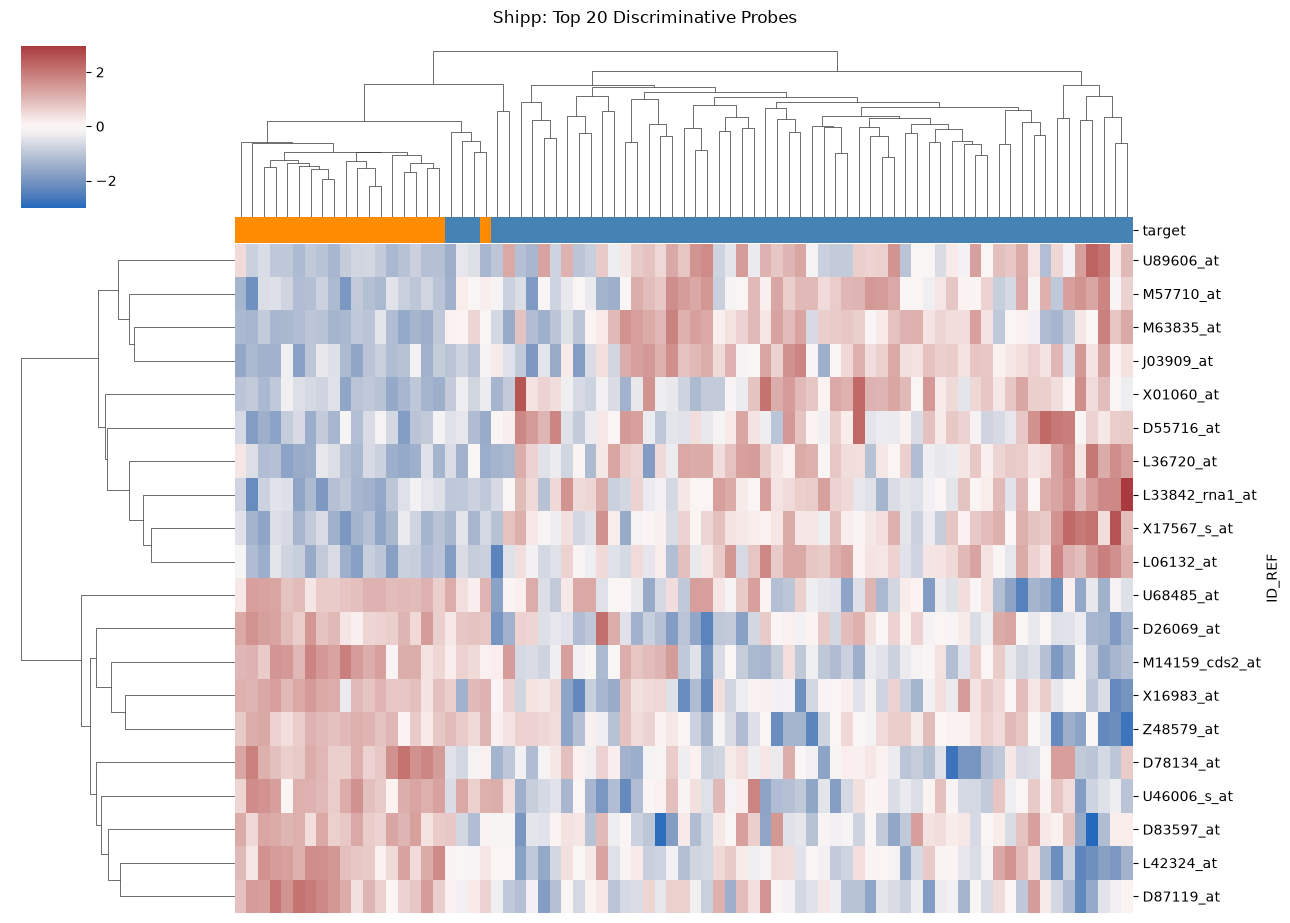

In [79]:
import seaborn as sns

top20_shipp = shipp_gene_stats.head(20)["probe"]
X_shipp_top20 = X_shipp_log[top20_shipp]

# Standardize each probe across patients
X_shipp_top20_z = (
    X_shipp_top20 - X_shipp_top20.mean()
) / X_shipp_top20.std()

shipp_class_colors = shipp_expr["target"].map({
    1: "steelblue",     # DLBCL
    0: "darkorange"     # FL
})

g_shipp20 = sns.clustermap(
    X_shipp_top20_z.T,
    col_colors=shipp_class_colors,
    cmap="vlag",
    center=0,
    figsize=(13, 9),
    xticklabels=False,
    yticklabels=True
)

g_shipp20.fig.suptitle(
    "Shipp: Top 20 Discriminative Probes",
    y=1.02
)

plt.show()

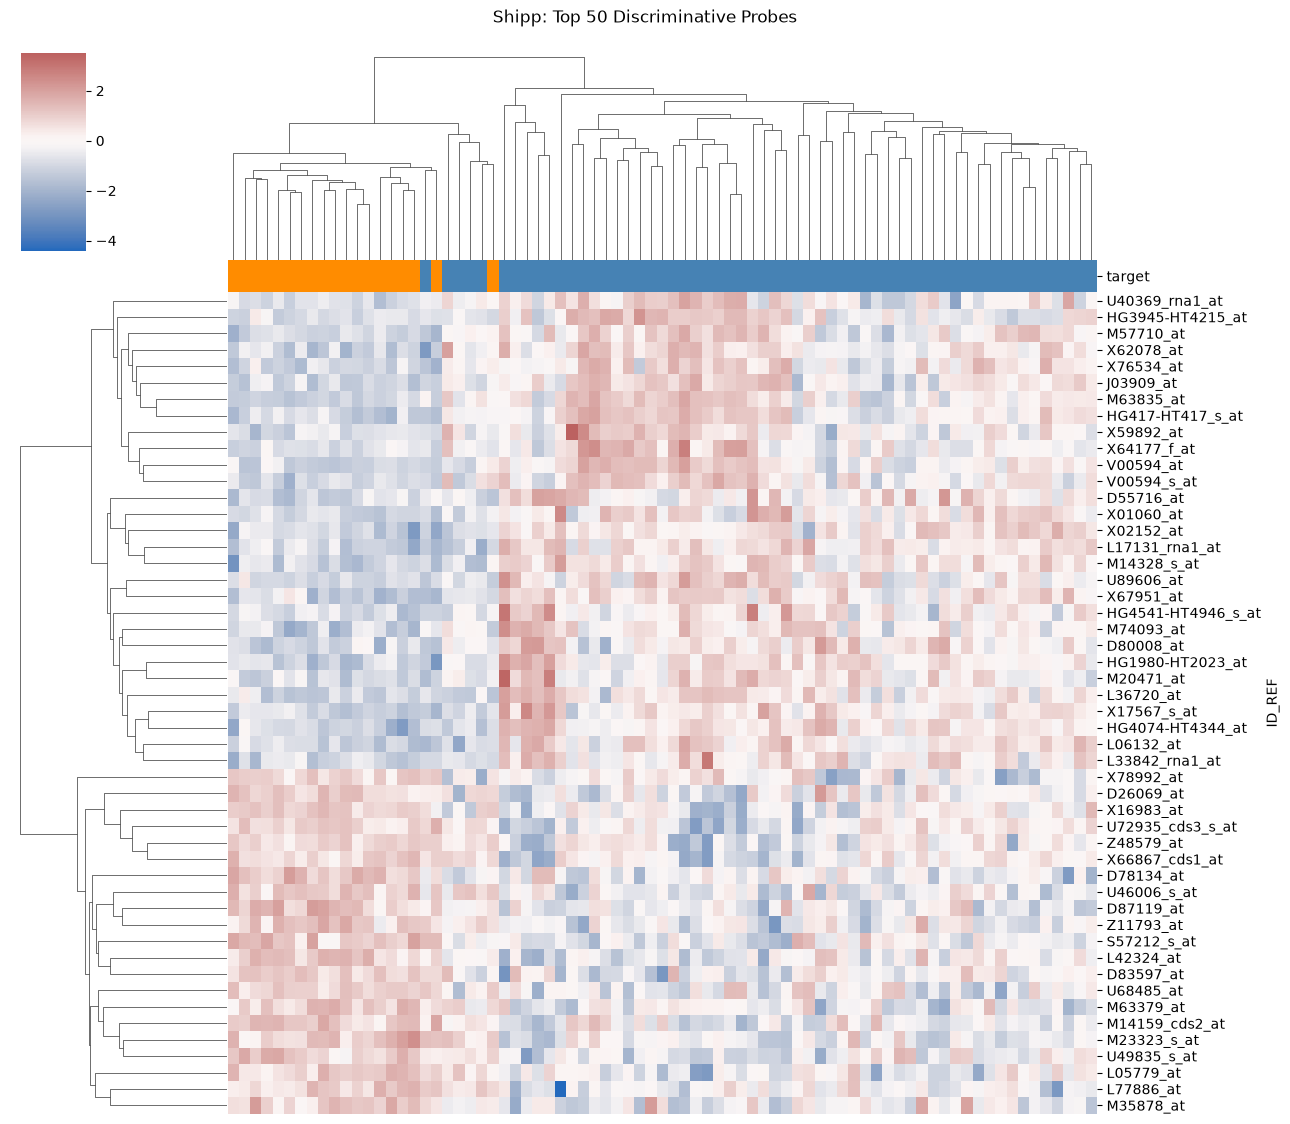

In [80]:
top50_shipp = shipp_gene_stats.head(50)["probe"]

X_shipp_top50 = X_shipp_log[top50_shipp]

X_shipp_top50_z = (
    X_shipp_top50 - X_shipp_top50.mean()
) / X_shipp_top50.std()

g_shipp50 = sns.clustermap(
    X_shipp_top50_z.T,
    col_colors=shipp_class_colors,
    cmap="vlag",
    center=0,
    figsize=(13, 11),
    xticklabels=False,
    yticklabels=True
)

g_shipp50.fig.suptitle(
    "Shipp: Top 50 Discriminative Probes",
    y=1.02
)

plt.show()